# House Price Prediction: Linear Regression vs Random Forest

**Project:** Comparative Analysis of Linear Regression and Random Forest for House Price Prediction
**Dataset:** Bengaluru House Price Data (Kaggle), file `data/Bengaluru_House_Data.csv`

This notebook contains the complete machine-learning part of the project, in order:

1. Dataset overview and verification
2. Data cleaning and train/test split
3. Exploratory data analysis (on the training data only)
4. Preprocessing pipeline
5. Model 1: Linear Regression
6. Model 2: Random Forest
7. Evaluation and comparison on the same test set
8. Saving the models and the preprocessing pipeline

**How to run:** put the notebook in the `notebooks/` folder of the project (CSV in `data/`), then use *Run All*. Every number and graph is produced by the code below; nothing is typed in by hand.

## 1. Setup

In [1]:
from pathlib import Path
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

# Project folders (works whether the notebook is run from notebooks/ or from the project root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "Bengaluru_House_Data.csv"
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
for d in (MODELS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Experiment settings
RANDOM_STATE = 42
TEST_SIZE = 0.2
MIN_LOCATION_COUNT = 10      # locations with <= 10 houses in the TRAIN set are grouped together
MIN_SQFT_PER_BHK = 300       # rows below this are treated as implausible
MAX_EXTRA_BATHS = 2          # rows with bath > bhk + 2 are treated as implausible

CATEGORICAL_FEATURES = ["location", "area_type"]
NUMERIC_FEATURES = ["total_sqft", "bhk", "bath", "balcony"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
TARGET = "price"             # lakhs of INR (confirm the unit on the Kaggle dataset page)
print("Project root:", ROOT)

Project root: /home/claude/house-price-prediction


## 2. Dataset overview

Source: https://www.kaggle.com/datasets/amitabhajoy/bengaluru-house-price-data
Licence: *to be filled in from the Kaggle page.*

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Rows, columns:", raw.shape)
print("\nColumns and types:")
print(raw.dtypes.to_string())
print("\nMissing values per column:")
print(raw.isnull().sum().to_string())
print("\nFully duplicated rows:", raw.duplicated().sum())
print("\nUnique values per column:")
print(raw.nunique().to_string())
raw.head()

Rows, columns: (13320, 9)

Columns and types:
area_type           str
availability        str
location            str
size                str
society             str
total_sqft          str
bath            float64
balcony         float64
price           float64

Missing values per column:
area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0

Fully duplicated rows: 529

Unique values per column:
area_type          4
availability      81
location        1305
size              31
society         2688
total_sqft      2117
bath              19
balcony            4
price           1994


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


**Column roles**

| Column | Type | Used as |
|---|---|---|
| `price` | numeric | **target** (lakhs of INR) |
| `total_sqft` | text with numbers, ranges and other units | numerical feature (after cleaning) |
| `size` | text such as "2 BHK" or "4 Bedroom" | converted to numerical feature `bhk` |
| `bath`, `balcony` | numeric | numerical features |
| `location`, `area_type` | text | categorical features |
| `society` | text, mostly missing | dropped |
| `availability` | text (ready to move or a date) | dropped |

## 3. Data cleaning

These rules work on single rows and use only the features, never the target, so applying them before the split does not leak test information.

* Drop `society` (about 41% missing, almost unique per project) and `availability` (not something a user would enter in a form).
* Tidy text spaces in `location` and `area_type`.
* Remove duplicate rows (done after dropping the two columns, so a copy of the same house cannot end up in both train and test).
* Remove rows missing `location`, `size` or `bath`.
* Convert `size` to a number of bedrooms (`bhk`).
* Convert `total_sqft` ranges such as "2100 - 2850" to their midpoint; remove rows in other units (square metres, acres, ...).
* Remove implausible rows: fewer than 300 sqft per bedroom, or more than 2 extra bathrooms compared with bedrooms.
* Missing `balcony` values are kept and filled later with the training-set median inside the pipeline.

In [3]:
def parse_sqft(value):
    """'1056' -> 1056.0 ; '2100 - 2850' -> midpoint ; other units (e.g. '34.46Sq. Meter') -> NaN."""
    s = str(value).strip()
    try:
        return float(s)
    except ValueError:
        pass
    m = re.fullmatch(r"(\d+\.?\d*)\s*-\s*(\d+\.?\d*)", s)
    return (float(m.group(1)) + float(m.group(2))) / 2 if m else np.nan


def clean_dataframe(raw):
    log = [f"Raw rows: {len(raw)}"]
    df = raw.drop(columns=["society", "availability"]).copy()
    for col in ["location", "area_type"]:
        df[col] = df[col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

    n = len(df); df = df.drop_duplicates()
    log.append(f"Removed duplicate rows: {n - len(df)}")

    n = len(df); df = df.dropna(subset=["location", "size", "bath"])
    log.append(f"Removed rows missing location/size/bath: {n - len(df)}")

    df["bhk"] = df["size"].str.extract(r"(\d+)", expand=False).astype(float)
    df = df.drop(columns=["size"])
    df["total_sqft"] = df["total_sqft"].apply(parse_sqft)

    n = len(df); df = df.dropna(subset=["total_sqft", "bhk"])
    log.append(f"Removed rows with total_sqft in unsupported units: {n - len(df)}")

    n = len(df); df = df[df["total_sqft"] / df["bhk"] >= MIN_SQFT_PER_BHK]
    log.append(f"Removed rows with < {MIN_SQFT_PER_BHK} sqft per bedroom: {n - len(df)}")

    n = len(df); df = df[df["bath"] <= df["bhk"] + MAX_EXTRA_BATHS]
    log.append(f"Removed rows with bath > bhk + {MAX_EXTRA_BATHS}: {n - len(df)}")

    df = df.reset_index(drop=True)
    log.append(f"Clean rows: {len(df)}")
    log.append(f"Remaining missing values (balcony): {int(df['balcony'].isna().sum())}")
    return df, log


clean, cleaning_log = clean_dataframe(raw)
print("\n".join(cleaning_log))
clean.head()

Raw rows: 13320
Removed duplicate rows: 692
Removed rows missing location/size/bath: 73
Removed rows with total_sqft in unsupported units: 46
Removed rows with < 300 sqft per bedroom: 733
Removed rows with bath > bhk + 2: 9
Clean rows: 11767
Remaining missing values (balcony): 434


,area_type,location,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,Electronic City Phase II,1056.0,2.0,1.0,39.07,2.0
1,Plot Area,Chikka Tirupathi,2600.0,5.0,3.0,120.00,4.0
2,Built-up Area,Uttarahalli,1440.0,2.0,3.0,62.00,3.0
3,Super built-up Area,Lingadheeranahalli,1521.0,3.0,1.0,95.00,3.0
4,Super built-up Area,Kothanur,1200.0,2.0,1.0,51.00,2.0


## 4. Train/test split

The data is split 80% / 20% with a fixed random seed. The test set is not used for EDA, for fitting the preprocessing, or for training. It is used only once, for the final evaluation.

In [4]:
X = clean[FEATURES]
y = clean[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (9413, 6) | Test: (2354, 6)


## 5. Exploratory data analysis (training data only)

Price (lakhs INR):
count    9413.00
mean      113.03
std       151.25
min         9.00
25%        50.00
50%        70.00
75%       120.00
max      2912.00

Skewness of price: 7.47
Skewness of log(1 + price): 0.93


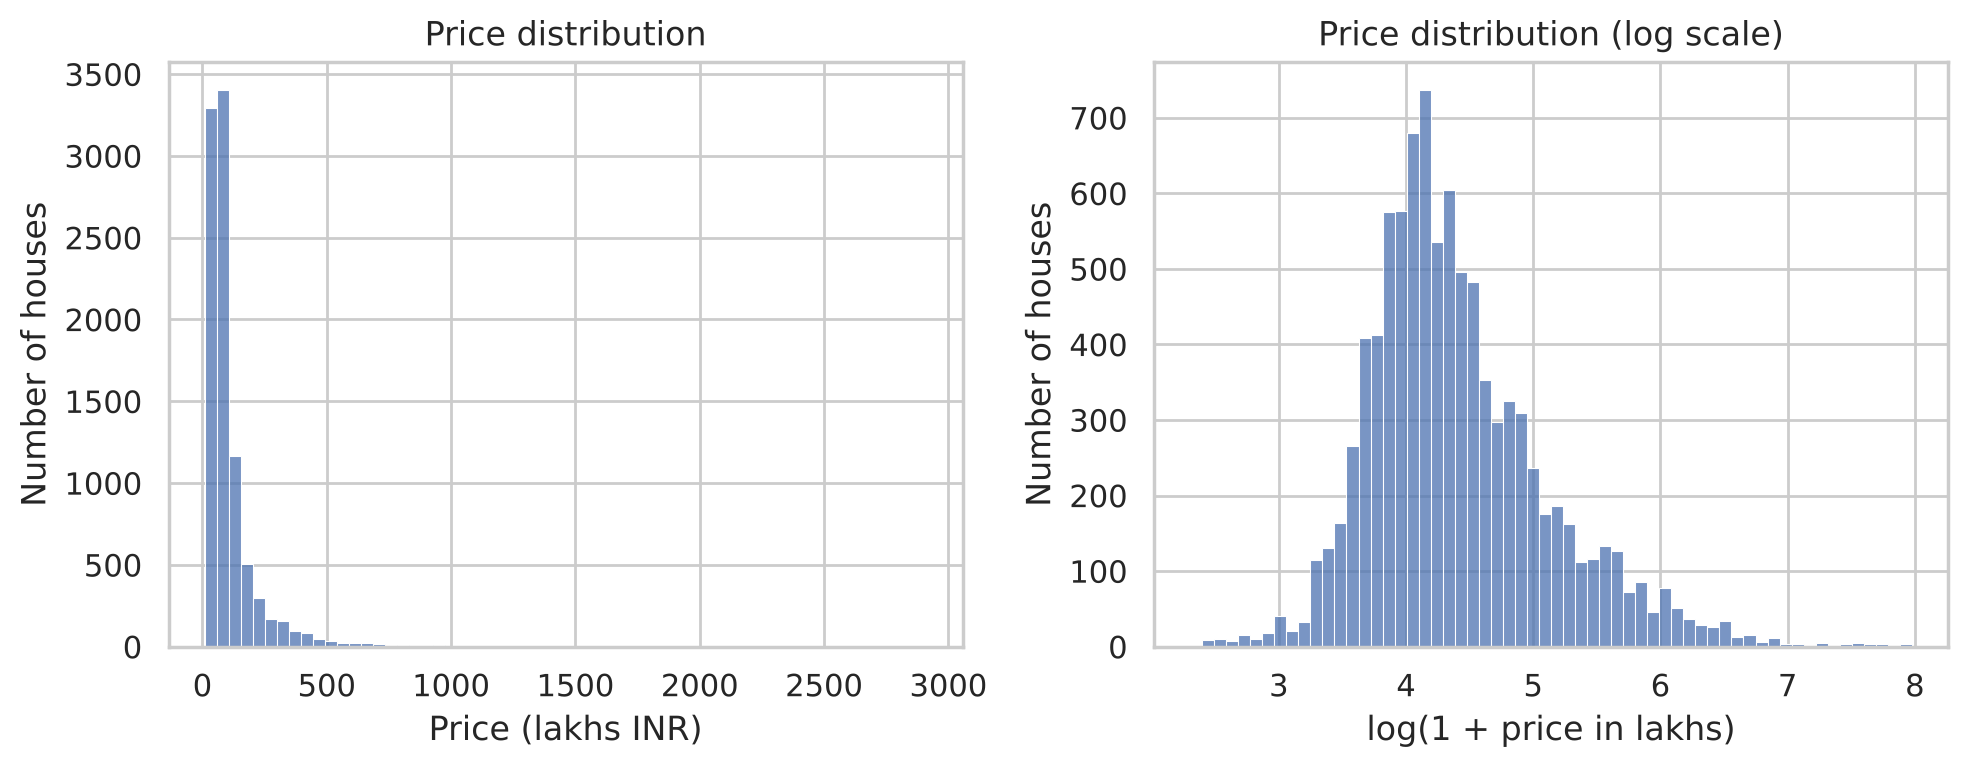

In [5]:
train_df = X_train.copy()
train_df["price"] = y_train
train_df["price_per_sqft"] = train_df["price"] * 100000 / train_df["total_sqft"]   # price in lakhs -> INR per sqft

print("Price (lakhs INR):")
print(train_df["price"].describe().round(2).to_string())
print(f"\nSkewness of price: {train_df['price'].skew():.2f}")
print(f"Skewness of log(1 + price): {np.log1p(train_df['price']).skew():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(train_df["price"], bins=60, ax=ax[0])
ax[0].set(title="Price distribution", xlabel="Price (lakhs INR)", ylabel="Number of houses")
sns.histplot(np.log1p(train_df["price"]), bins=60, ax=ax[1])
ax[1].set(title="Price distribution (log scale)", xlabel="log(1 + price in lakhs)", ylabel="Number of houses")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_price_distribution.png", dpi=200); plt.show()

**Observation.** Prices are strongly right-skewed: most houses are cheap and a small number are very expensive. A log transform makes the shape much closer to symmetric. This matters for Linear Regression, which fits a straight line and is pulled by extreme values.

       total_sqft      bhk     bath  balcony
count     9413.00  9413.00  9413.00  9071.00
mean      1602.41     2.67     2.58     1.60
std       1218.30     1.00     1.09     0.81
min        300.00     1.00     1.00     0.00
25%       1120.00     2.00     2.00     1.00
50%       1308.00     3.00     2.00     2.00
75%       1719.00     3.00     3.00     2.00
max      52272.00    16.00    16.00     3.00


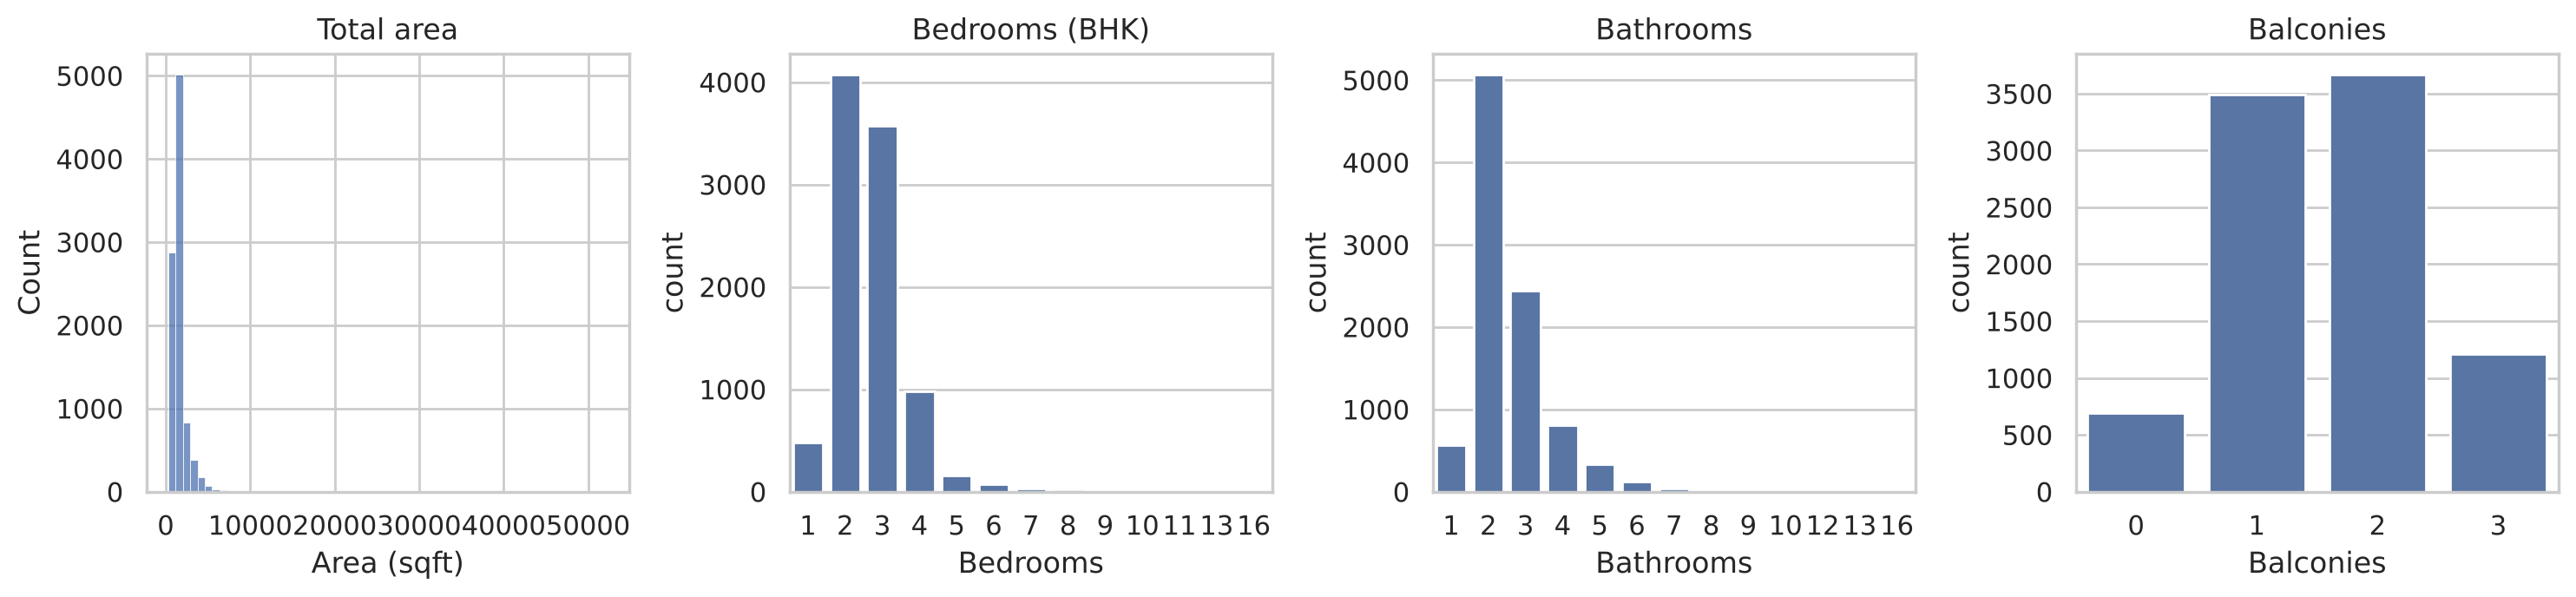

In [6]:
print(train_df[NUMERIC_FEATURES].describe().round(2).to_string())

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
sns.histplot(train_df["total_sqft"], bins=60, ax=ax[0]); ax[0].set(title="Total area", xlabel="Area (sqft)")
sns.countplot(x=train_df["bhk"].astype(int), ax=ax[1]); ax[1].set(title="Bedrooms (BHK)", xlabel="Bedrooms")
sns.countplot(x=train_df["bath"].astype(int), ax=ax[2]); ax[2].set(title="Bathrooms", xlabel="Bathrooms")
sns.countplot(x=train_df["balcony"].dropna().astype(int), ax=ax[3]); ax[3].set(title="Balconies", xlabel="Balconies")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_feature_distributions.png", dpi=200); plt.show()

**Observation.** Most houses have 2 or 3 bedrooms and 2 or 3 bathrooms. Total area is concentrated at lower values with a long tail of very large entries.

Median price (lakhs) by number of bedrooms:
      count  median
bhk                
1.0     482    34.4
2.0    4073    54.5
3.0    3571    90.0
4.0     982   220.0
5.0     158   250.0
6.0      73   214.0
7.0      30   155.0
8.0      24   197.5
9.0      12   200.0
10.0      4   325.0
11.0      2   255.0
13.0      1   275.0
16.0      1   550.0


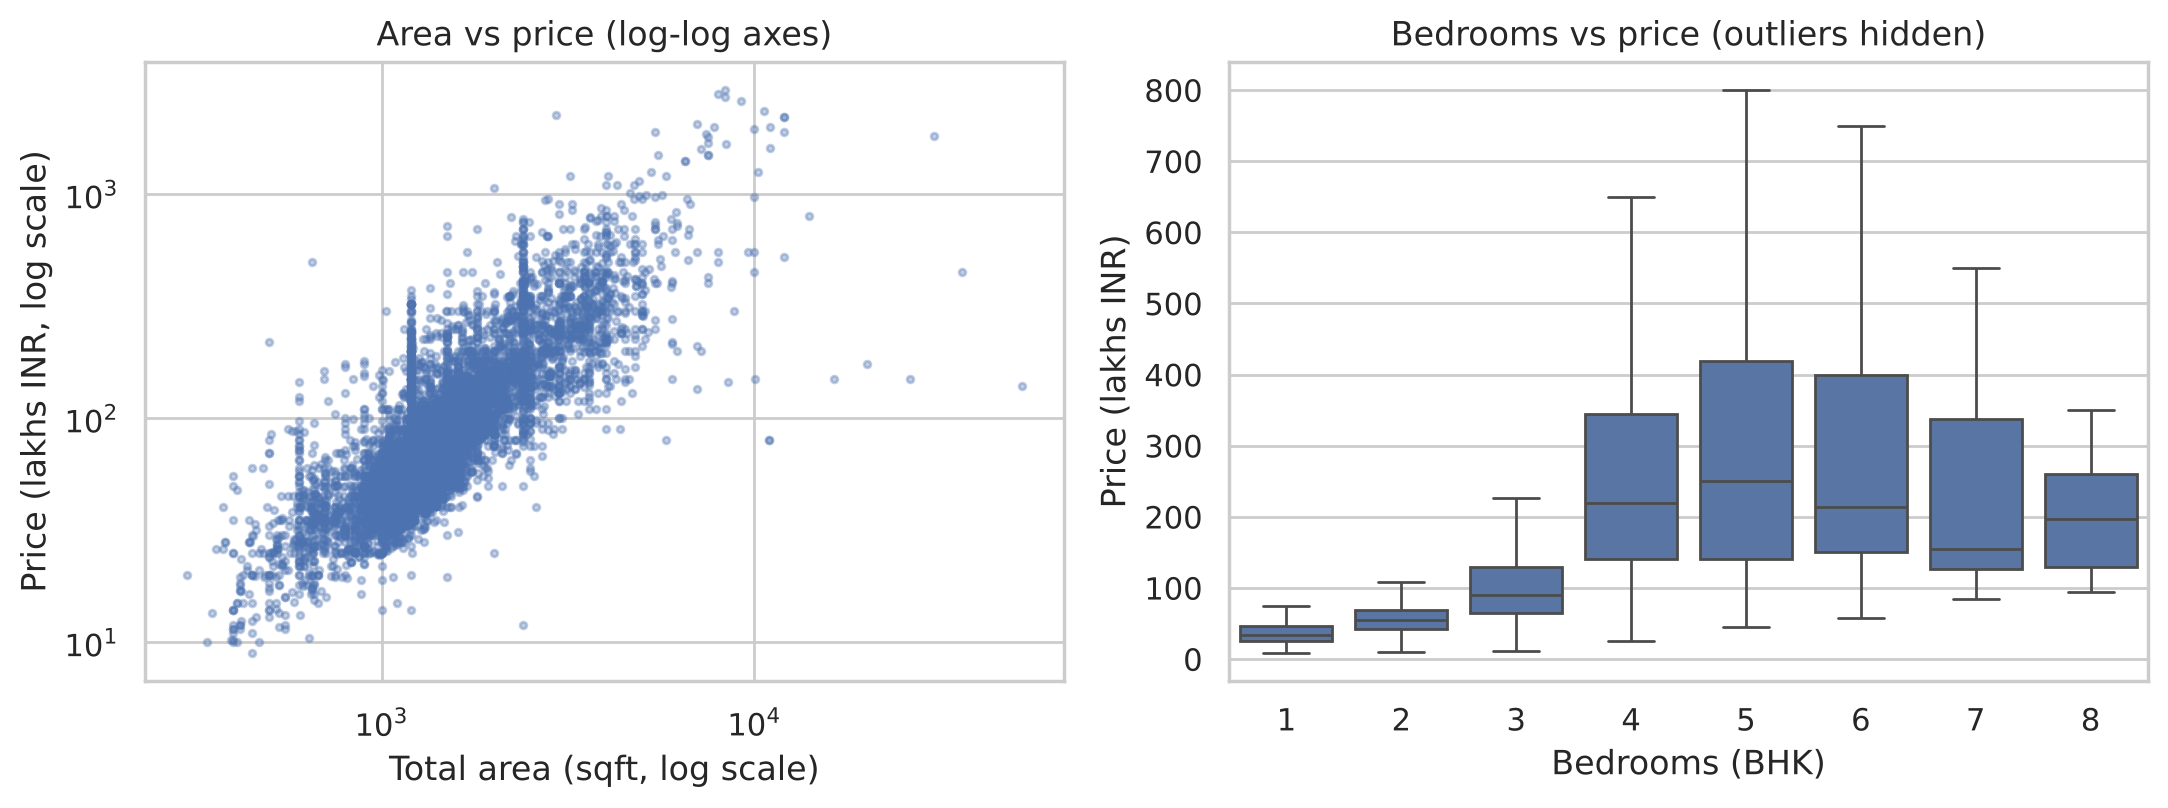

In [7]:
print("Median price (lakhs) by number of bedrooms:")
print(train_df.groupby("bhk")["price"].agg(["count", "median"]).round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(train_df["total_sqft"], train_df["price"], s=6, alpha=0.35)
ax[0].set(xscale="log", yscale="log", title="Area vs price (log-log axes)",
          xlabel="Total area (sqft, log scale)", ylabel="Price (lakhs INR, log scale)")
bhk_plot = train_df[train_df["bhk"] <= 8]
sns.boxplot(x=bhk_plot["bhk"].astype(int), y=bhk_plot["price"], ax=ax[1], showfliers=False)
ax[1].set(title="Bedrooms vs price (outliers hidden)", xlabel="Bedrooms (BHK)", ylabel="Price (lakhs INR)")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_area_bedrooms_vs_price.png", dpi=200); plt.show()

**Observation.** Price rises with area and with the number of bedrooms. The area-price relationship looks roughly linear on log-log axes but is widely scattered, so area alone does not determine price.

Spearman correlation with price:
total_sqft    0.807
bhk           0.692
bath          0.715
balcony       0.206


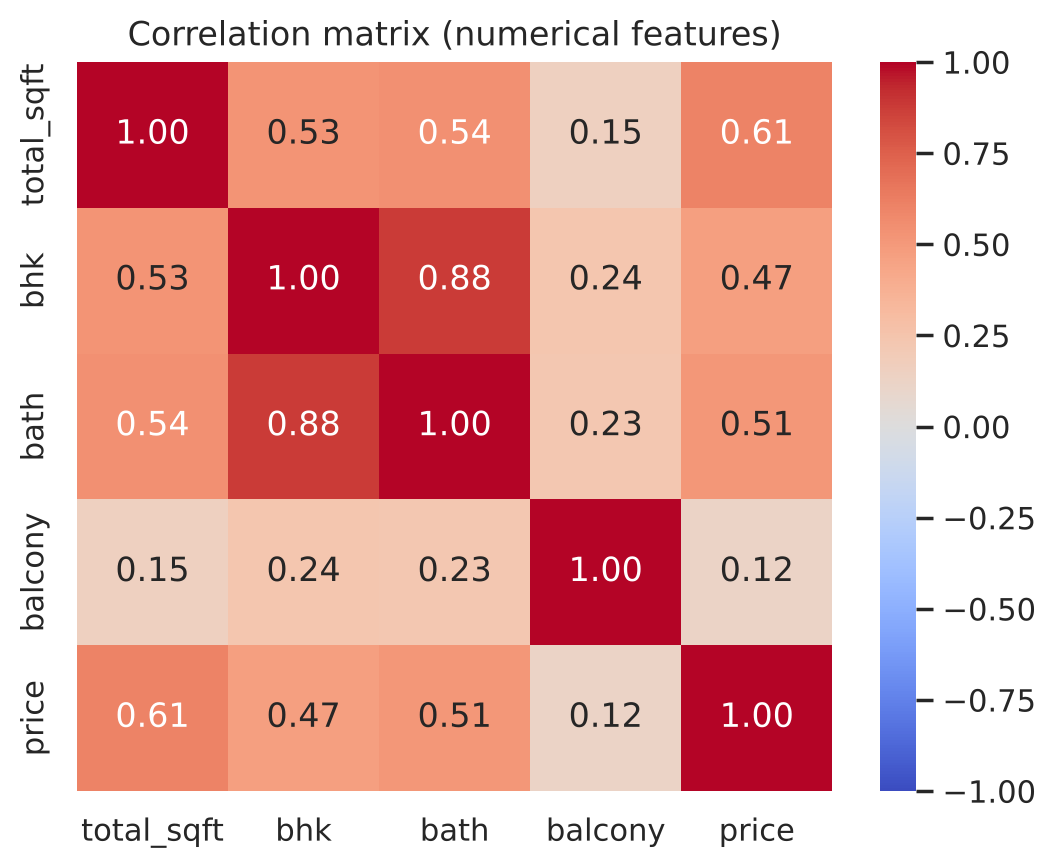

In [8]:
corr = train_df[NUMERIC_FEATURES + ["price"]].corr()
print("Spearman correlation with price:")
print(train_df[NUMERIC_FEATURES].corrwith(train_df["price"], method="spearman").round(3).to_string())

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix (numerical features)")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_correlation_matrix.png", dpi=200); plt.show()

**Observation.** `total_sqft` has the strongest correlation with price. `bhk` and `bath` are highly correlated with each other (they carry similar information), and `balcony` has only a weak relationship with price. Highly correlated inputs are a known issue for the coefficients of Linear Regression, but not for prediction accuracy in a tree model.

                     count  median   mean
area_type                                
Built-up Area         1842    70.0  106.0
Carpet Area             70    69.5   91.9
Plot Area             1040   155.5  239.1
Super built-up Area   6461    65.4   95.0

Top 10 locations by median price (at least 30 houses):
                   count  median
location                        
Malleshwaram          45   275.0
Rajaji Nagar          74   259.5
Indira Nagar          32   195.5
Thigalarapalya        32   150.5
Koramangala           62   145.0
Hegde Nagar           36   124.0
Talaghattapura        31   121.0
Hebbal               116   115.0
Harlur                54   113.5
Green Glen Layout     34   113.5

Distinct locations in training data: 1109


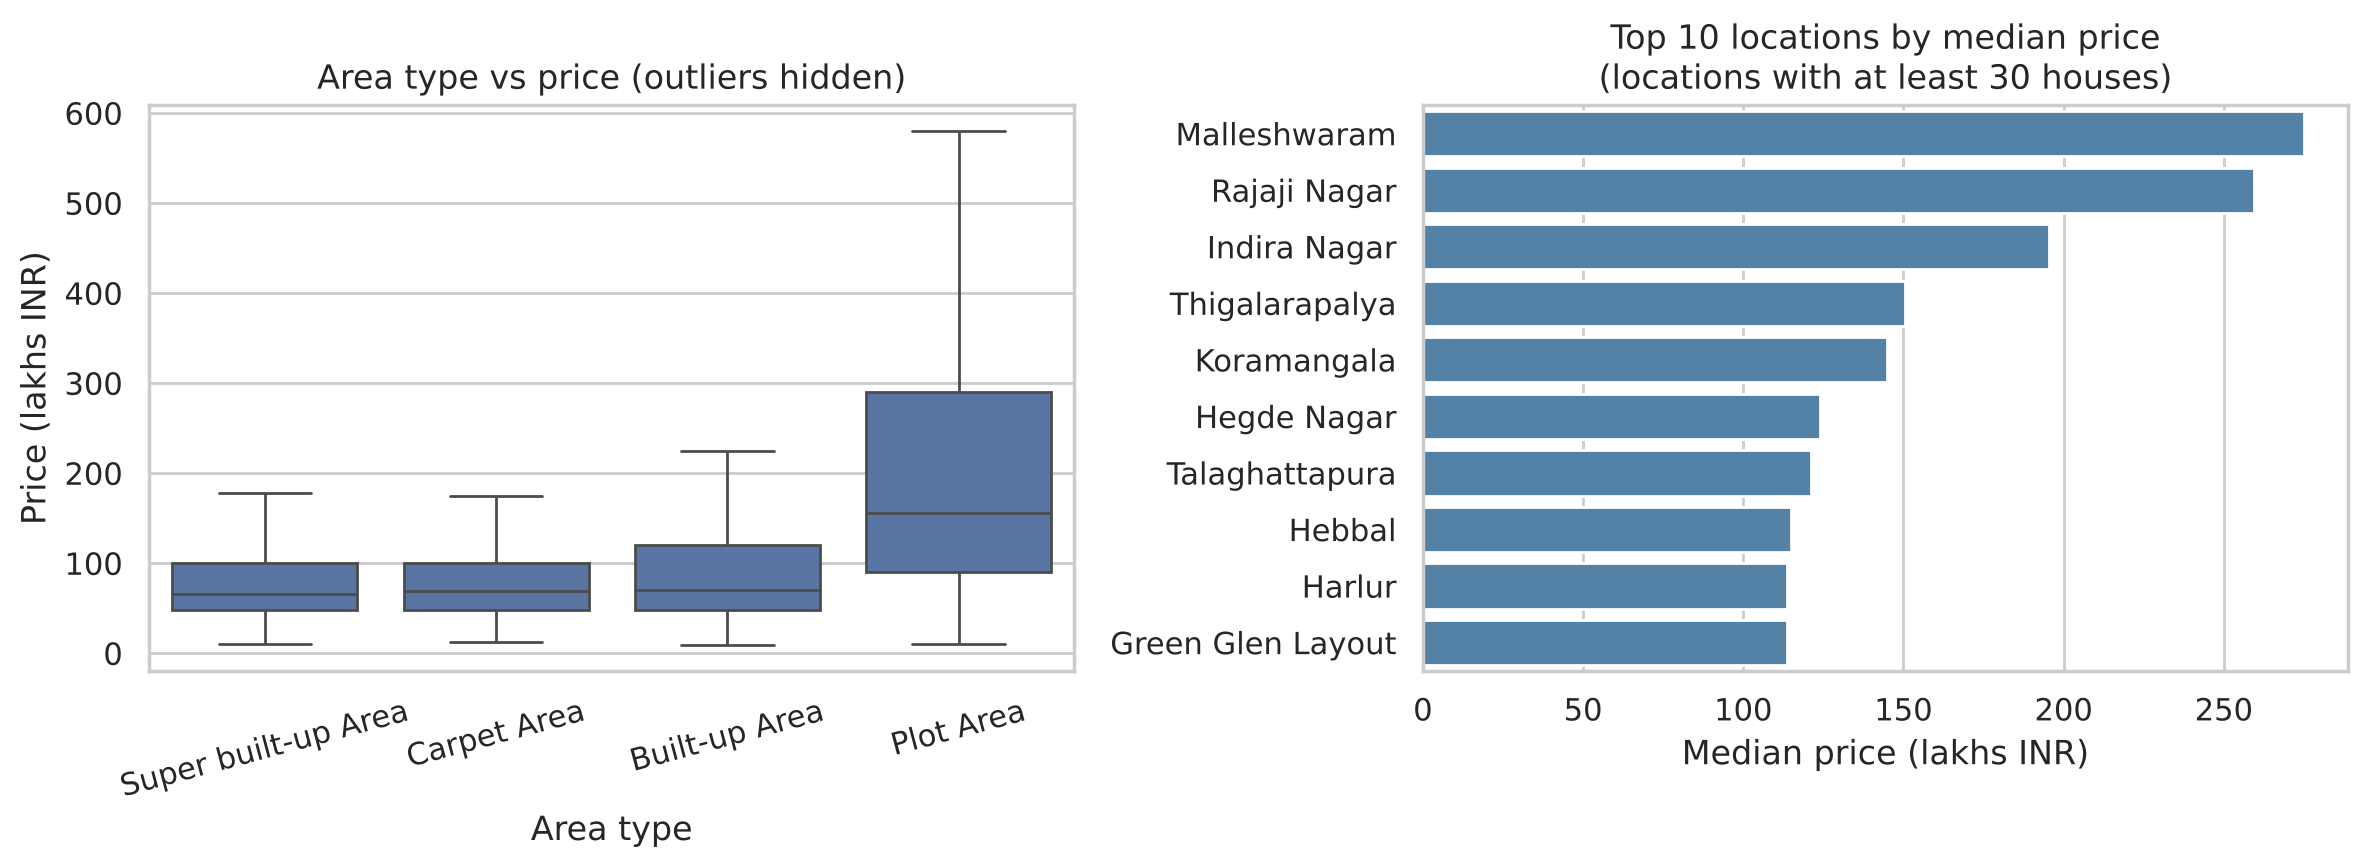

In [9]:
print(train_df.groupby("area_type")["price"].agg(["count", "median", "mean"]).round(1).to_string())
loc_stats = train_df.groupby("location")["price"].agg(["count", "median"])
top_locations = loc_stats[loc_stats["count"] >= 30].sort_values("median", ascending=False).head(10)
print("\nTop 10 locations by median price (at least 30 houses):")
print(top_locations.round(1).to_string())
print("\nDistinct locations in training data:", train_df["location"].nunique())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
order = train_df.groupby("area_type")["price"].median().sort_values().index
sns.boxplot(x="area_type", y="price", data=train_df, order=order, ax=ax[0], showfliers=False)
ax[0].set(title="Area type vs price (outliers hidden)", xlabel="Area type", ylabel="Price (lakhs INR)")
ax[0].tick_params(axis="x", rotation=15)
sns.barplot(x=top_locations["median"], y=top_locations.index, ax=ax[1], color="steelblue")
ax[1].set(title="Top 10 locations by median price\n(locations with at least 30 houses)",
          xlabel="Median price (lakhs INR)", ylabel="")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_categorical_analysis.png", dpi=200); plt.show()

**Observation.** Plot Area listings have a much higher median price than the other area types, and some locations are clearly more expensive than others. With over a thousand distinct locations, most of them have very few houses, which is why rare locations are grouped in the preprocessing step.

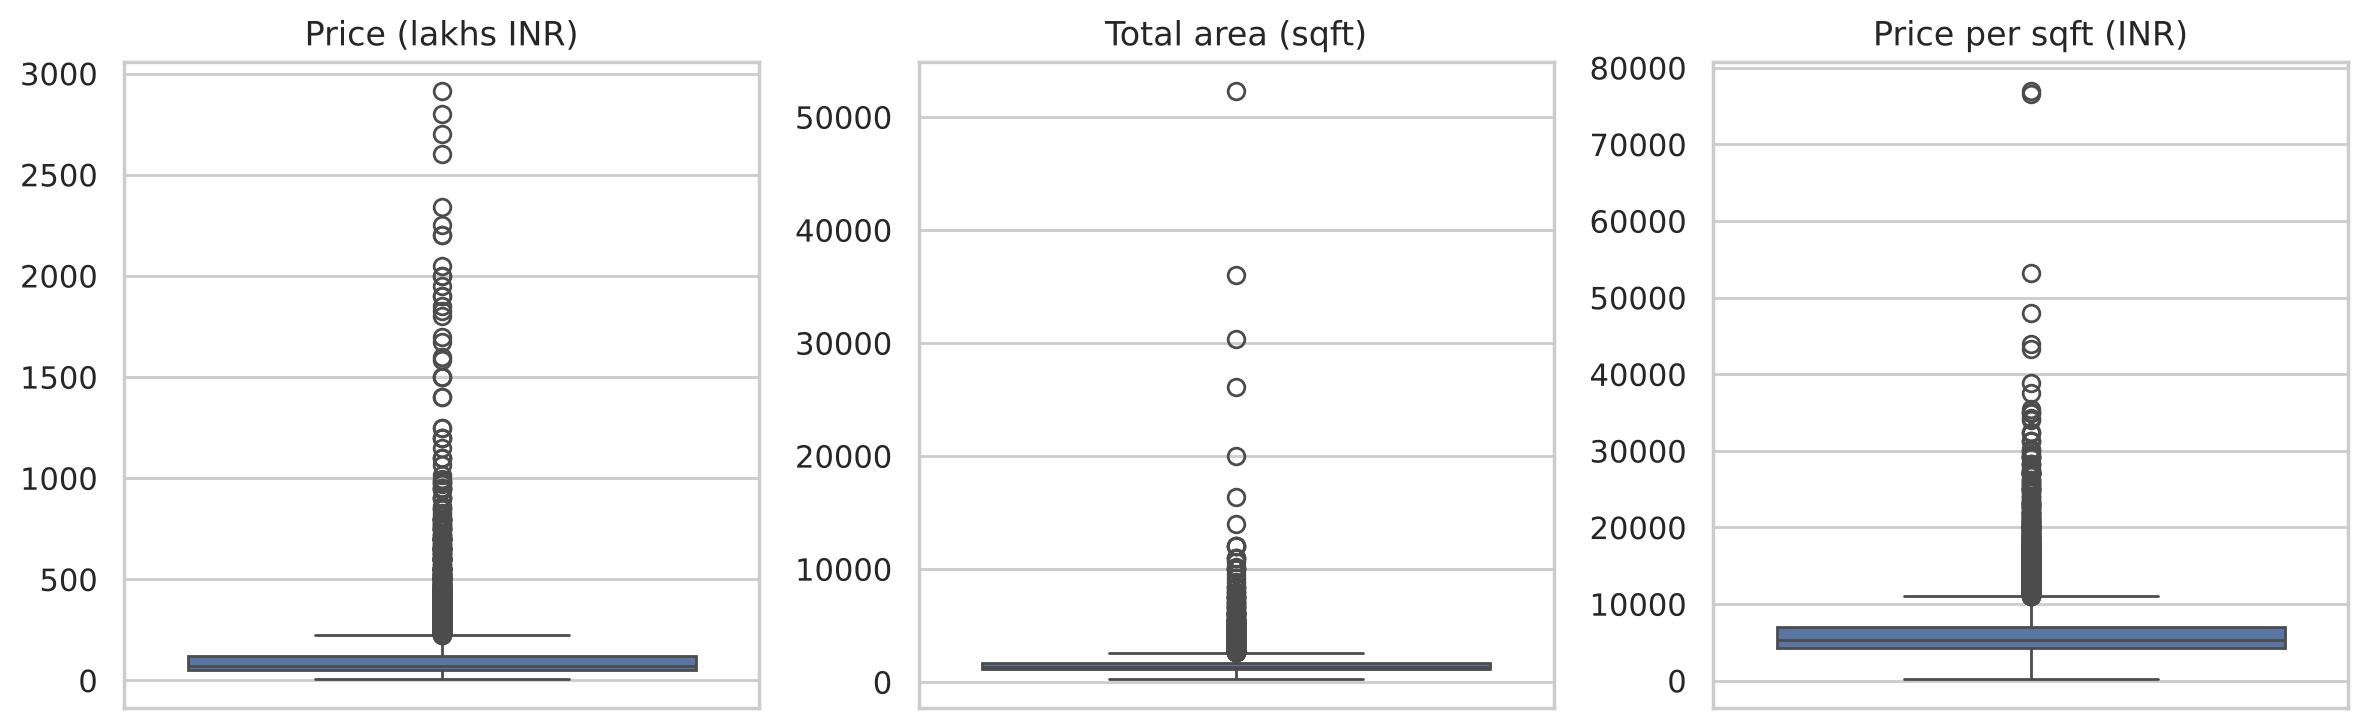

Outliers by the 1.5 x IQR rule (kept in the data; shown for transparency):
  price: 912 rows (9.7%) outside [-55.0, 225.0]
  total_sqft: 850 rows (9.0%) outside [221.5, 2617.5]
  bath: 538 rows (5.7%) outside [0.5, 4.5]
  price_per_sqft: 776 rows (8.2%) outside [140.0, 11100.0]

Five largest total_sqft values in training data: [52272.0, 36000.0, 30400.0, 26136.0, 20000.0]


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
for a, col, title in zip(ax, ["price", "total_sqft", "price_per_sqft"],
                         ["Price (lakhs INR)", "Total area (sqft)", "Price per sqft (INR)"]):
    sns.boxplot(y=train_df[col], ax=a); a.set(title=title, ylabel="")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_outlier_analysis.png", dpi=200); plt.show()

print("Outliers by the 1.5 x IQR rule (kept in the data; shown for transparency):")
for col in ["price", "total_sqft", "bath", "price_per_sqft"]:
    q1, q3 = train_df[col].quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n = int(((train_df[col] < lo) | (train_df[col] > hi)).sum())
    print(f"  {col}: {n} rows ({n / len(train_df) * 100:.1f}%) outside [{lo:.1f}, {hi:.1f}]")
print("\nFive largest total_sqft values in training data:", train_df["total_sqft"].nlargest(5).tolist())

**Observation.** A substantial share of rows are statistical outliers in price and area. Only implausible rows (by the rules in Section 3) were removed; genuine expensive or large properties are kept, because they are real market data that a house-price model should handle. A few very large area values remain and are discussed in the results.

## 6. Preprocessing pipeline

The pipeline is fitted on the **training data only** and then applied unchanged to the test data and (later) to user input in the web application.

* Numerical features (`total_sqft`, `bhk`, `bath`, `balcony`): missing values filled with the training median, then standardised.
* Categorical features (`location`, `area_type`): one-hot encoded. Locations with 10 or fewer houses in the training data are grouped into one "infrequent" category, and unseen locations at prediction time fall into that same category.

The same transformed data is given to both models, so the comparison is fair.

In [11]:
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
categorical_enc = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=MIN_LOCATION_COUNT + 1,     # categories seen <= 10 times are grouped as infrequent
    sparse_output=False)

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC_FEATURES),
    ("cat", categorical_enc, CATEGORICAL_FEATURES),
])

preprocessor.fit(X_train)                     # fitted on training data only
Xtr = preprocessor.transform(X_train)
Xte = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print("Transformed training shape:", Xtr.shape)
print("Transformed test shape:    ", Xte.shape)
print("Balcony median used for imputation:", preprocessor.named_transformers_["num"].named_steps["imputer"].statistics_[3])
print("Distinct location columns after grouping rare ones:",
      sum(n.startswith("cat__location") for n in feature_names))

Transformed training shape: (9413, 193)
Transformed test shape:     (2354, 193)
Balcony median used for imputation: 2.0
Distinct location columns after grouping rare ones: 185


## 7. Model 1: Linear Regression

**Why:** it is the simplest regression baseline. It is fast, easy to interpret (each coefficient shows how the price changes with a feature) and is the standard point of comparison for more flexible models.

**Assumptions (and how they apply here):**
* The relationship between the features and price is linear.
* Errors are independent with roughly constant variance. House prices are skewed, so this assumption is only partly met.
* Little multicollinearity among inputs. `bhk` and `bath` are strongly correlated.
* Numerical features should be on similar scales and missing values handled: done by the pipeline.

**Training:** ordinary least squares on the preprocessed training data.

In [12]:
lr_model = LinearRegression()
lr_model.fit(Xtr, y_train)
print("Linear Regression trained on", len(y_train), "rows with", lr_model.coef_.shape[0], "input columns.")

Linear Regression trained on 9413 rows with 193 input columns.


## 8. Model 2: Random Forest Regressor

**Why:** it is an ensemble of decision trees that can capture non-linear relationships and interactions between features (for example, area matters differently by location) without assuming a straight-line relationship. It is also less sensitive to outliers and does not need scaled inputs.

**Hyperparameters (set in advance, not tuned on the test set):**

| Parameter | Value |
|---|---|
| `n_estimators` (number of trees) | 100 |
| `min_samples_leaf` | 3 |
| `random_state` | 42 |
| all others | scikit-learn defaults |

`min_samples_leaf=3` limits how deep trees grow, which reduces over-fitting and keeps the saved file small.

In [13]:
N_ESTIMATORS = 100
MIN_SAMPLES_LEAF = 3

rf_model = RandomForestRegressor(
    n_estimators=N_ESTIMATORS,
    min_samples_leaf=MIN_SAMPLES_LEAF,
    random_state=RANDOM_STATE,
    n_jobs=-1)
rf_model.fit(Xtr, y_train)
print(f"Random Forest trained: {N_ESTIMATORS} trees, min_samples_leaf={MIN_SAMPLES_LEAF}, random_state={RANDOM_STATE}")

Random Forest trained: 100 trees, min_samples_leaf=3, random_state=42


## 9. Evaluation on the same test set

Metrics: **MAE** (mean absolute error), **MSE** (mean squared error), **RMSE** (square root of MSE, in the same unit as price) and **R²** (share of variance explained). Prices are in lakhs of INR.

In [14]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": float(np.sqrt(mse)), "R2": r2_score(y_true, y_pred)}

models = {"Linear Regression": lr_model, "Random Forest": rf_model}
test_pred = {name: m.predict(Xte) for name, m in models.items()}

comparison = pd.DataFrame(
    [{"Model": n, **regression_metrics(y_test, p)} for n, p in test_pred.items()]).round(4)
train_metrics = pd.DataFrame(
    [{"Model": n, **regression_metrics(y_train, m.predict(Xtr))} for n, m in models.items()]).round(4)

print("TEST-SET RESULTS")
display(comparison)
print("TRAIN-SET RESULTS (over-fitting check)")
display(train_metrics)

TEST-SET RESULTS


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,41.4529,11942.9397,109.2838,0.4165
1,Random Forest,33.5975,7906.3129,88.9175,0.6137


TRAIN-SET RESULTS (over-fitting check)


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,42.2637,11875.6050,108.9752,0.4808
1,Random Forest,24.9048,4099.5835,64.0280,0.8208


**Cross-validation.** To check that the test result is not a lucky split, both models are also evaluated with 5-fold cross-validation on the training data only. The preprocessing is re-fitted inside every fold.

In [15]:
cv_rows = []
for name, model in models.items():
    pipe = Pipeline([("pre", clone(preprocessor)), ("model", clone(model))])
    cv = cross_validate(pipe, X_train, y_train, cv=5,
                        scoring=["neg_root_mean_squared_error", "r2"])
    cv_rows.append({"Model": name,
                    "CV RMSE mean": -cv["test_neg_root_mean_squared_error"].mean(),
                    "CV RMSE std": cv["test_neg_root_mean_squared_error"].std(),
                    "CV R2 mean": cv["test_r2"].mean(), "CV R2 std": cv["test_r2"].std()})
cv_df = pd.DataFrame(cv_rows).round(4)
display(cv_df)

,Model,CV RMSE mean,CV RMSE std,CV R2 mean,CV R2 std
0,Linear Regression,117.2283,23.8123,0.3708,0.2306
1,Random Forest,91.4117,7.6065,0.6170,0.0760


## 10. Model comparison

Final comparison table (test set):


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,41.4529,11942.9397,109.2838,0.4165
1,Random Forest,33.5975,7906.3129,88.9175,0.6137


Better model by test RMSE: Random Forest


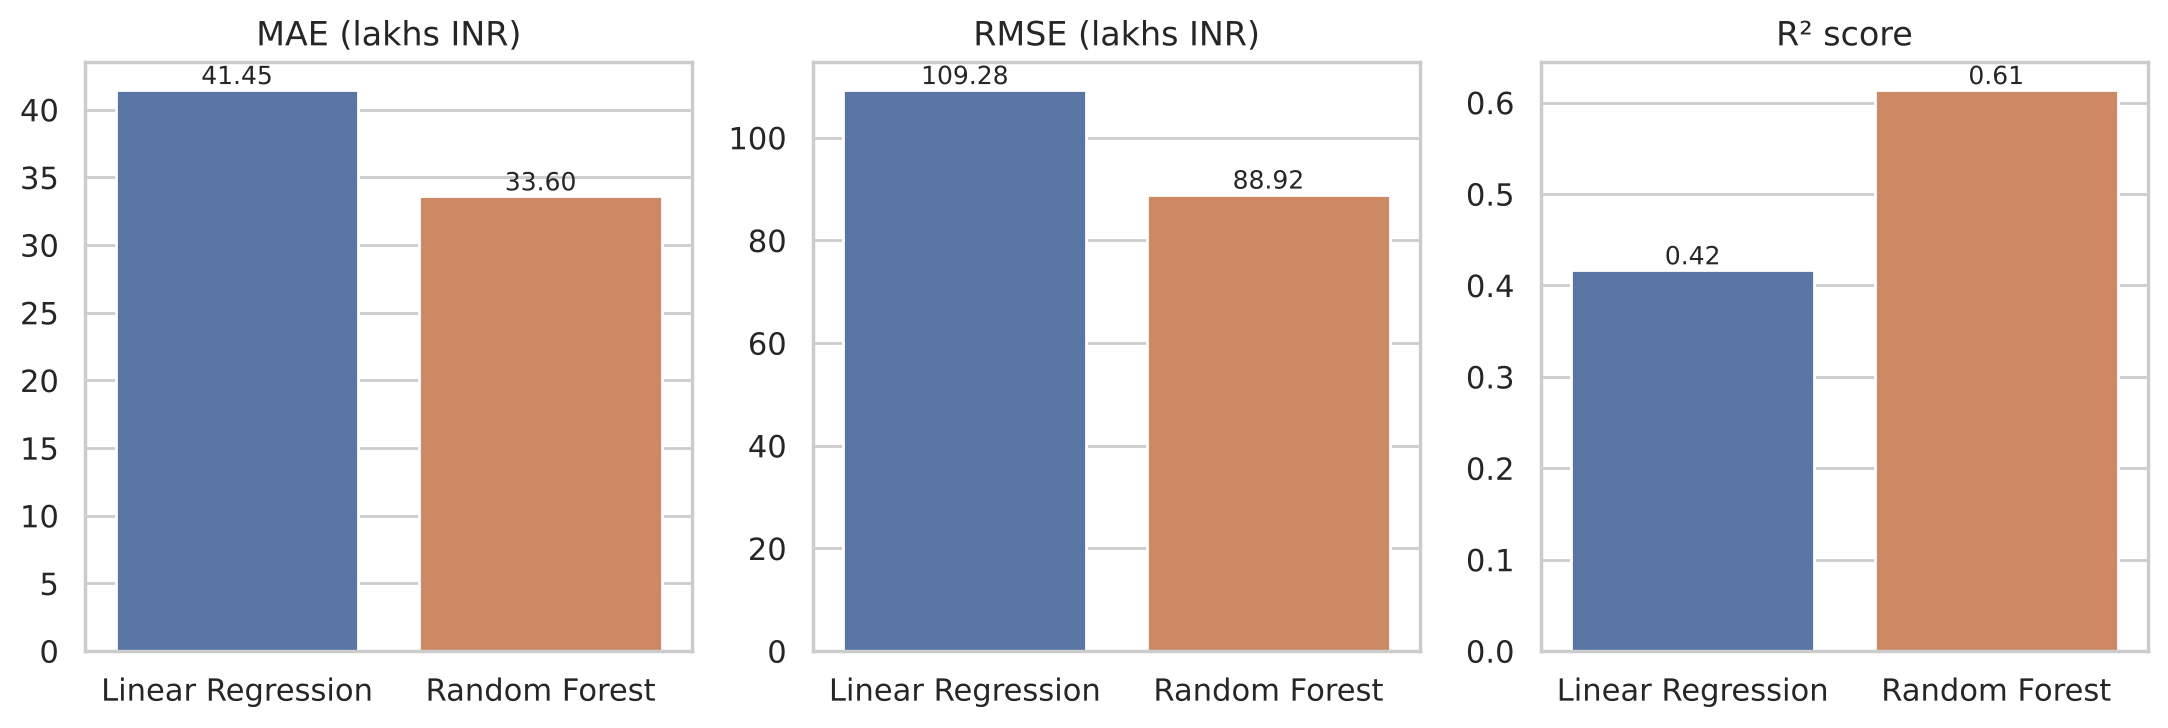

In [16]:
best_model = comparison.sort_values("RMSE").iloc[0]["Model"]
print("Final comparison table (test set):")
display(comparison)
print(f"Better model by test RMSE: {best_model}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, metric, label in zip(axes, ["MAE", "RMSE", "R2"], ["MAE (lakhs INR)", "RMSE (lakhs INR)", "R² score"]):
    sns.barplot(x="Model", y=metric, data=comparison, ax=ax, hue="Model", legend=False)
    ax.set(title=label, xlabel="", ylabel="")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=9)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "result_model_comparison.png", dpi=200); plt.show()

### Actual vs predicted

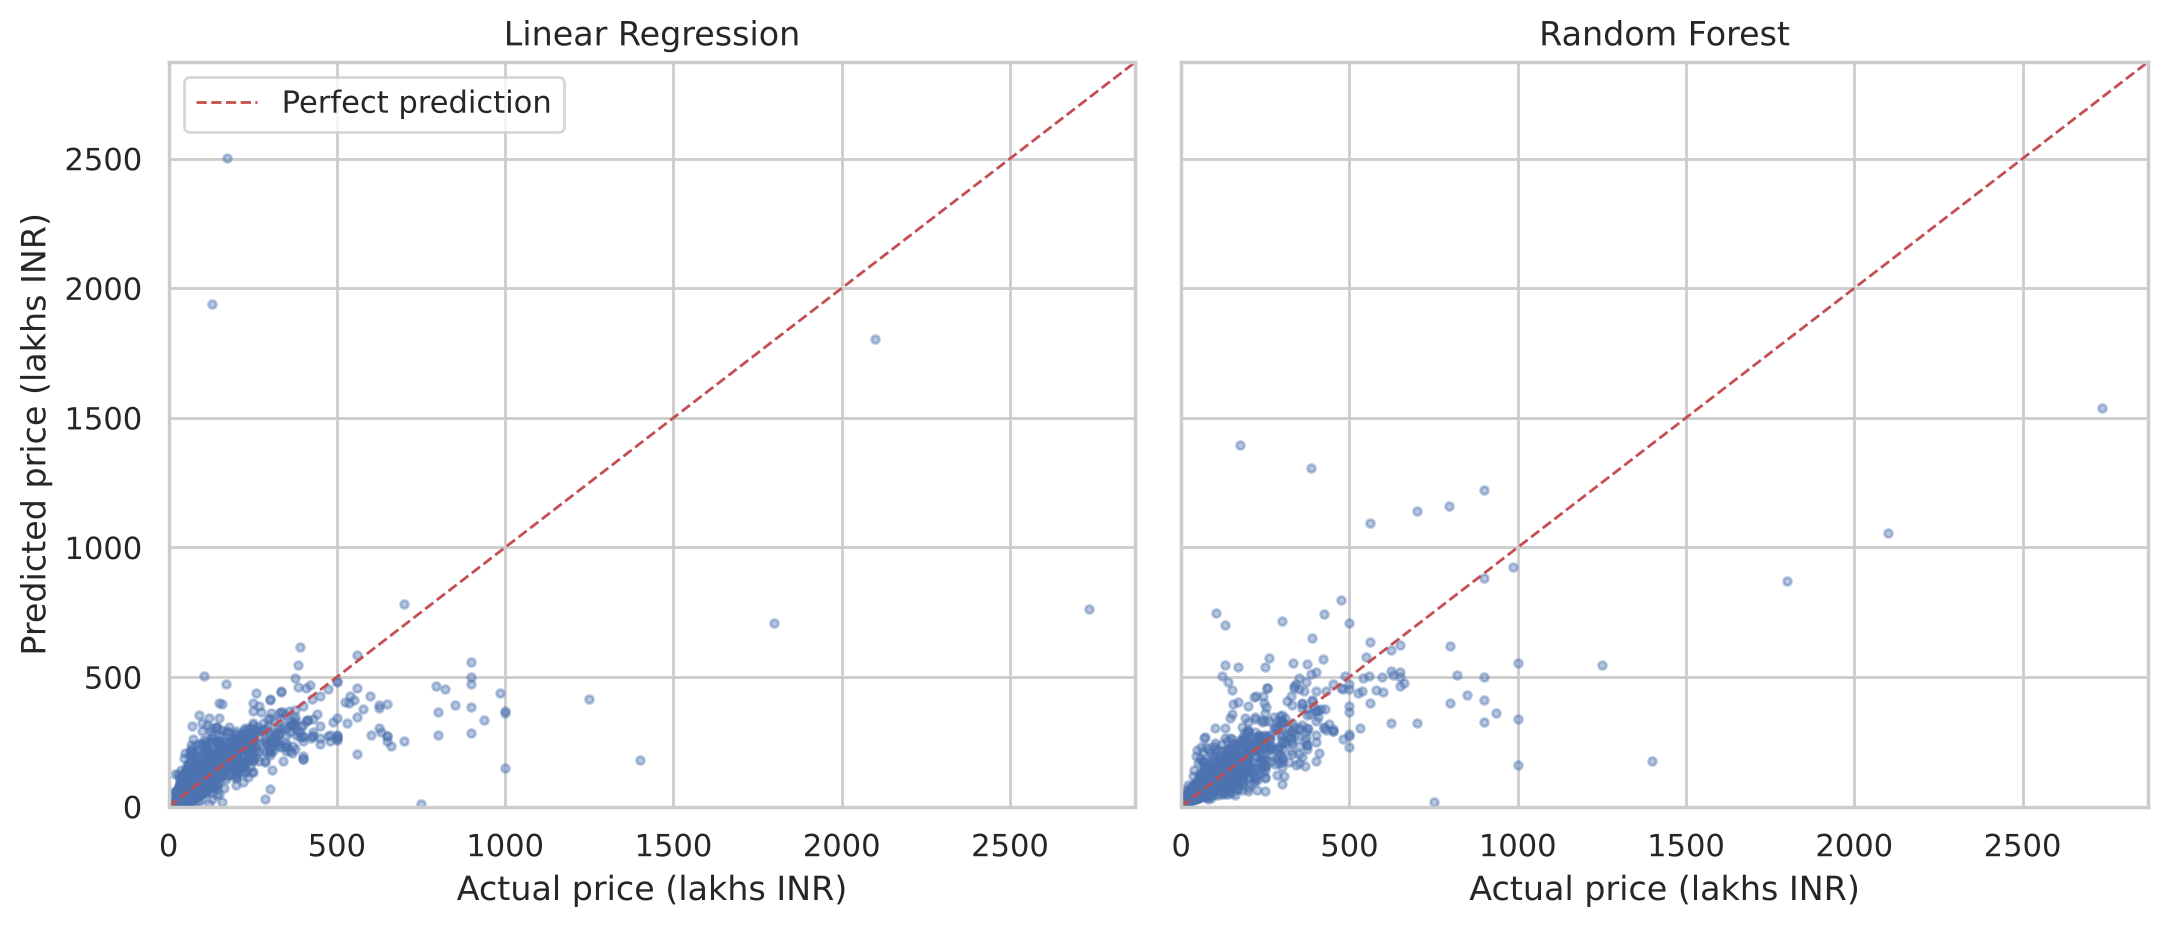

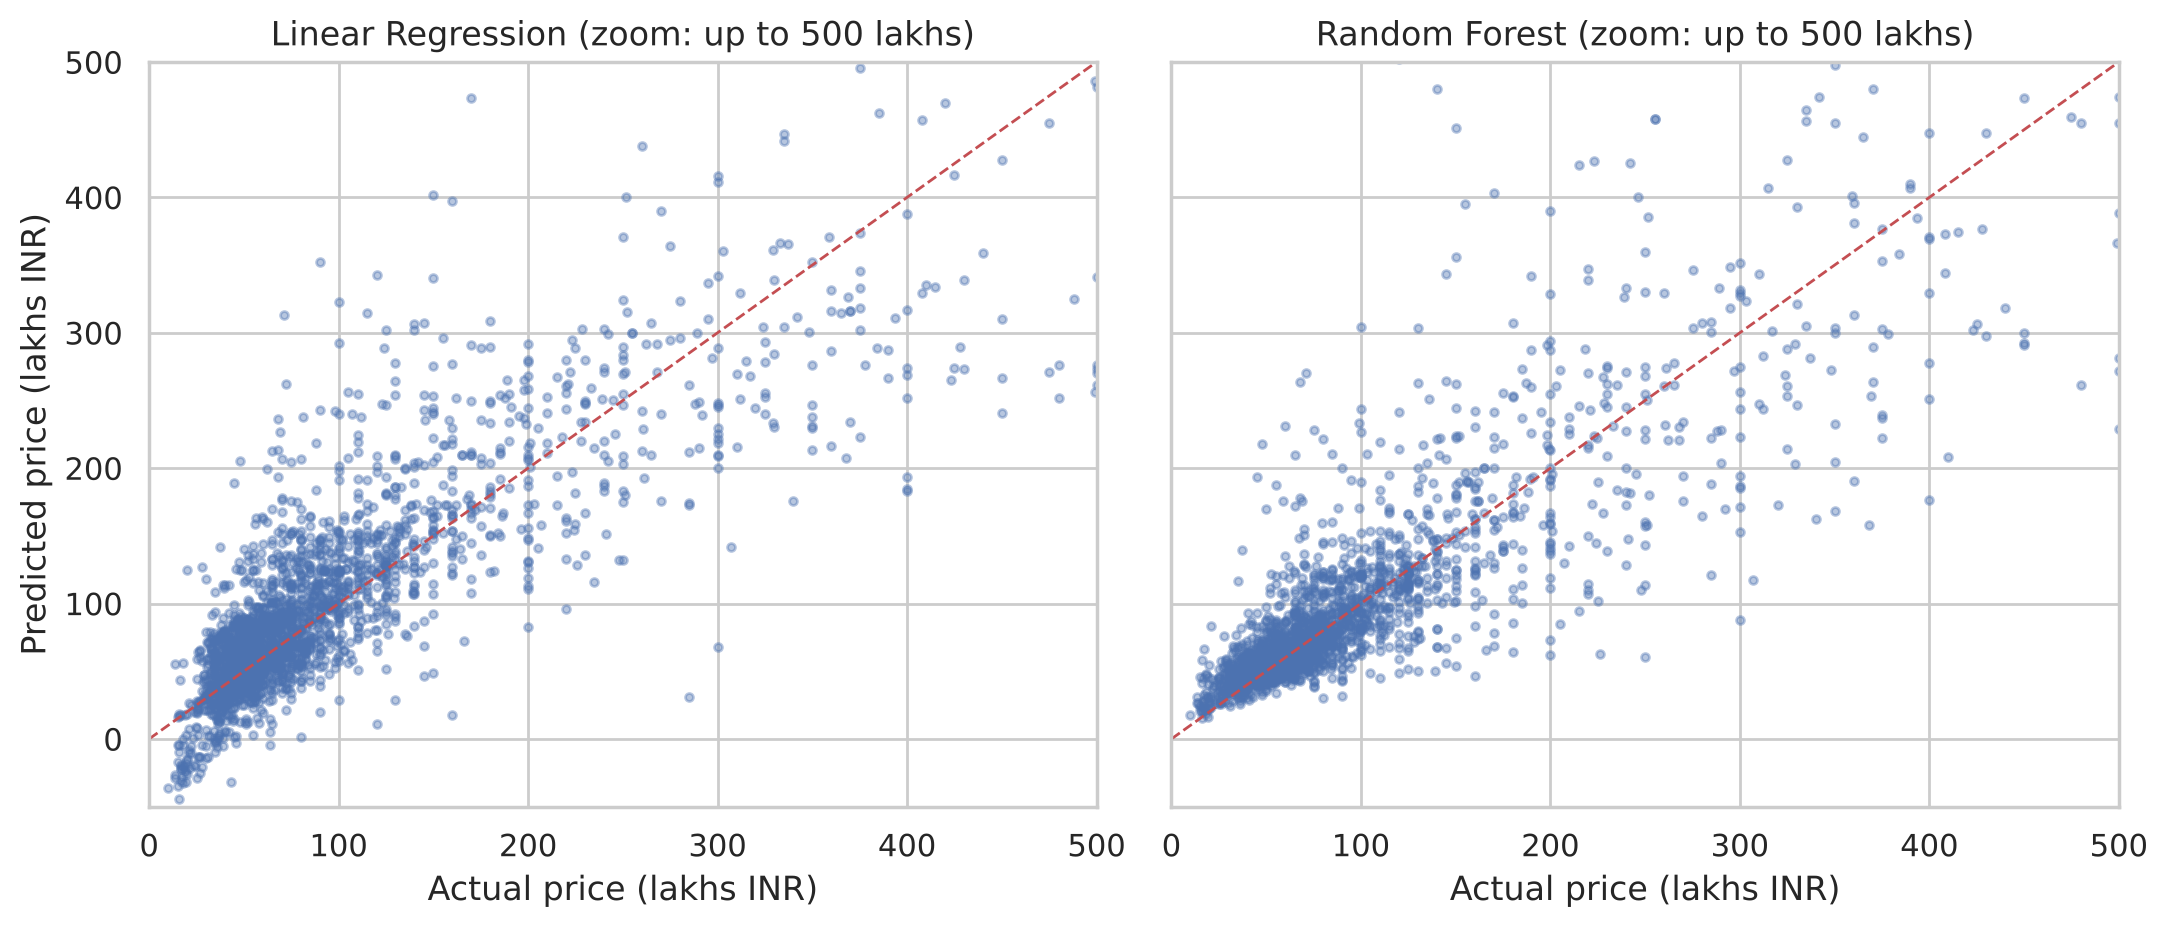

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
lim = [0, float(max(y_test.max(), max(p.max() for p in test_pred.values()))) * 1.05]
for ax, (name, p) in zip(axes, test_pred.items()):
    ax.scatter(y_test, p, s=8, alpha=0.4)
    ax.plot(lim, lim, "r--", lw=1, label="Perfect prediction")
    ax.set(title=name, xlabel="Actual price (lakhs INR)", xlim=lim, ylim=lim)
axes[0].set_ylabel("Predicted price (lakhs INR)"); axes[0].legend()
plt.tight_layout(); plt.savefig(FIGURES_DIR / "result_actual_vs_predicted.png", dpi=200); plt.show()

# Zoomed view of the bulk of the data
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, test_pred.items()):
    ax.scatter(y_test, p, s=8, alpha=0.4)
    ax.plot([0, 500], [0, 500], "r--", lw=1)
    ax.set(title=f"{name} (zoom: up to 500 lakhs)", xlabel="Actual price (lakhs INR)", xlim=(0, 500), ylim=(-50, 500))
axes[0].set_ylabel("Predicted price (lakhs INR)")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "result_actual_vs_predicted_zoom.png", dpi=200); plt.show()

### Random Forest feature importance

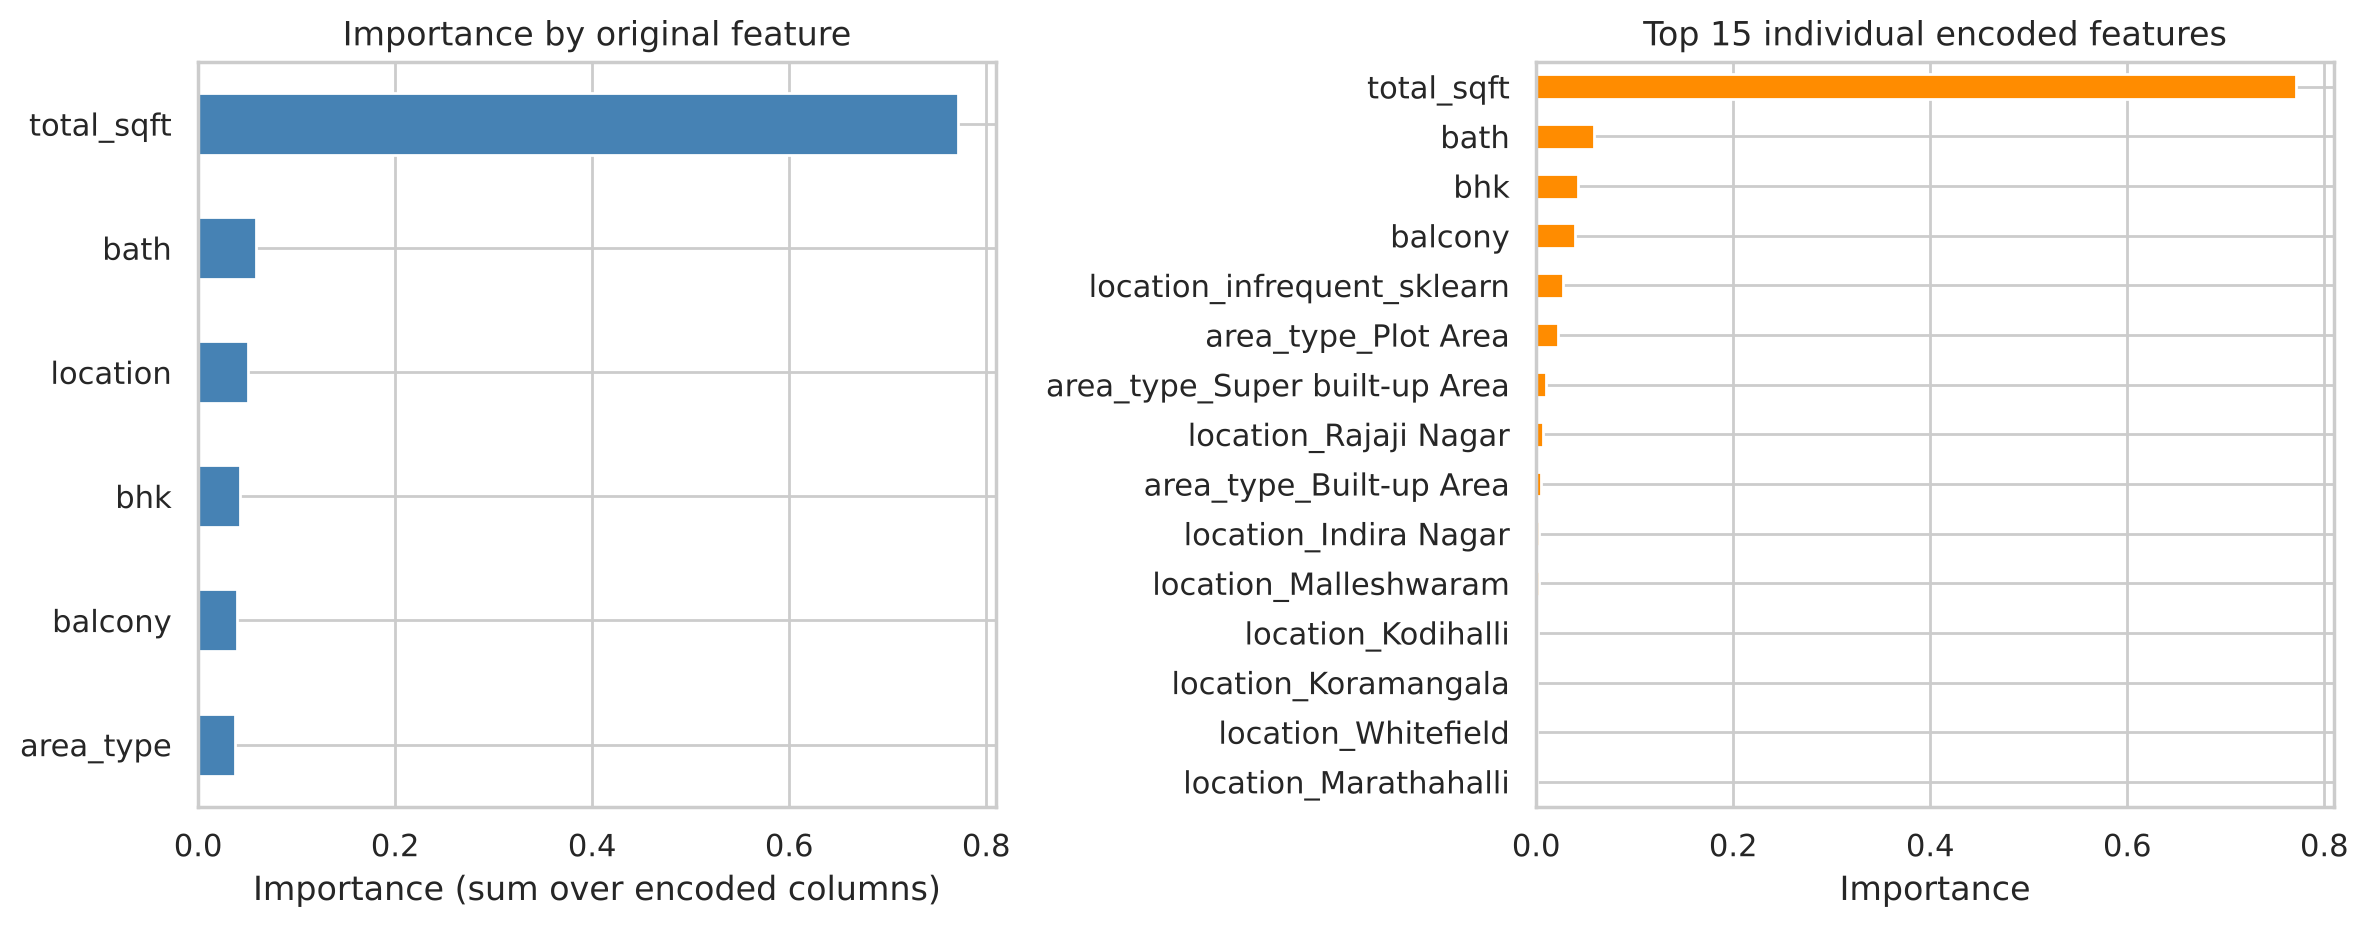

total_sqft    0.7712
bath          0.0588
location      0.0511
bhk           0.0425
balcony       0.0392
area_type     0.0371


In [18]:
def original_feature(name):
    if name.startswith("num__"):
        return name[len("num__"):]
    return "location" if name.startswith("cat__location") else "area_type"

importance = pd.Series(rf_model.feature_importances_, index=feature_names)
by_feature = importance.groupby(original_feature).sum().sort_values()
top15 = importance.sort_values().tail(15)
top15.index = [i.replace("num__", "").replace("cat__", "") for i in top15.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
by_feature.plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="Importance by original feature", xlabel="Importance (sum over encoded columns)")
top15.plot.barh(ax=axes[1], color="darkorange")
axes[1].set(title="Top 15 individual encoded features", xlabel="Importance")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "result_rf_feature_importance.png", dpi=200); plt.show()
print(by_feature.sort_values(ascending=False).round(4).to_string())

### Diagnostics used in the discussion

In [19]:
lr_pred = test_pred["Linear Regression"]
print(f"Linear Regression: {int((lr_pred < 0).sum())} of {len(lr_pred)} test predictions are negative "
      f"(lowest {lr_pred.min():.2f} lakhs).")
for name, p in test_pred.items():
    err = np.abs(y_test.values - p)
    print(f"{name}: median absolute error {np.median(err):.2f} lakhs, "
          f"median absolute % error {np.median(err / y_test.values) * 100:.1f}%")

worst = pd.Series(lr_pred, index=X_test.index).sort_values(ascending=False).head(3).index
worst_df = X_test.loc[worst].copy()
worst_df["actual_price"] = y_test.loc[worst]
worst_df["LR_prediction"] = pd.Series(lr_pred, index=X_test.index).loc[worst].round(0)
worst_df["RF_prediction"] = rf_model.predict(preprocessor.transform(X_test.loc[worst])).round(0)
print("\nThree highest Linear Regression predictions on the test set:")
display(worst_df)

Linear Regression: 55 of 2354 test predictions are negative (lowest -44.73 lakhs).
Linear Regression: median absolute error 22.03 lakhs, median absolute % error 26.9%
Random Forest: median absolute error 12.85 lakhs, median absolute % error 18.1%

Three highest Linear Regression predictions on the test set:


,location,area_type,total_sqft,bhk,bath,balcony,actual_price,LR_prediction,RF_prediction
4913,Doddabommasandra,Super built-up Area,42000.0,9.0,8.0,3.0,175.0,2501.0,1396.0
633,Yelahanka,Built-up Area,35000.0,3.0,3.0,3.0,130.0,1940.0,702.0
2420,Dodsworth Layout,Plot Area,30000.0,4.0,4.0,NaN,2100.0,1803.0,1055.0


## 11. Discussion of the results

In [20]:
lr_t = comparison.set_index("Model").loc["Linear Regression"]
rf_t = comparison.set_index("Model").loc["Random Forest"]
rf_tr = train_metrics.set_index("Model").loc["Random Forest"]
print(f"On the test set, Random Forest has RMSE {rf_t['RMSE']:.2f} vs {lr_t['RMSE']:.2f} for Linear Regression "
      f"({(1 - rf_t['RMSE'] / lr_t['RMSE']) * 100:.1f}% lower), MAE {rf_t['MAE']:.2f} vs {lr_t['MAE']:.2f}, "
      f"and R2 {rf_t['R2']:.3f} vs {lr_t['R2']:.3f}.")
print(f"Random Forest R2 is {rf_tr['R2']:.3f} on the training data but {rf_t['R2']:.3f} on the test data: "
      "it fits the training data much better than new data (over-fitting).")

On the test set, Random Forest has RMSE 88.92 vs 109.28 for Linear Regression (18.6% lower), MAE 33.60 vs 41.45, and R2 0.614 vs 0.416.
Random Forest R2 is 0.821 on the training data but 0.614 on the test data: it fits the training data much better than new data (over-fitting).


**Why Random Forest performs better here (reasoning, supported by the outputs above):**

* The data is skewed and noisy, and the relationship between area, location and price is not a single straight line. Random Forest can model non-linear effects and interactions; Linear Regression cannot.
* Linear Regression extrapolates linearly, so houses with extreme area values get extreme (even negative) predictions. A tree-based model cannot predict beyond the range of prices seen in training, so it is more stable on such rows.
* The Random Forest feature-importance chart shows area carries most of the predictive weight, while the many location categories each contribute little.

**Limitations**

* Single city (Bengaluru), listing prices rather than final sale prices.
* The dataset has no parking, property age or number of floors.
* Cleaning rules (e.g. the 300 sqft per bedroom rule) are judgement calls; a few extreme area values remain.
* Hyperparameters were fixed, not tuned. Random Forest over-fits the training data to some degree.
* Both models predict the raw price; a log-price target was not tested.

## 12. Save the models and preprocessing pipeline

The web application will load these files; it will **not** retrain anything.

In [21]:
joblib.dump(preprocessor, MODELS_DIR / "preprocessor.pkl")
joblib.dump(lr_model, MODELS_DIR / "linear_regression.pkl")
joblib.dump(rf_model, MODELS_DIR / "random_forest.pkl", compress=3)

comparison.to_csv(RESULTS_DIR / "comparison.csv", index=False)
pd.DataFrame({"actual_price": y_test.values,
              "pred_linear_regression": test_pred["Linear Regression"],
              "pred_random_forest": test_pred["Random Forest"]}).round(2).to_csv(
    RESULTS_DIR / "test_predictions.csv", index=False)

report = ["TEST-SET RESULTS (price in lakhs INR; MAE/RMSE in lakhs, MSE in lakhs^2)",
          comparison.to_string(index=False), "",
          "TRAIN-SET RESULTS", train_metrics.to_string(index=False), "",
          "5-FOLD CROSS-VALIDATION ON TRAIN DATA", cv_df.to_string(index=False), "",
          f"Better model by test RMSE: {best_model}",
          f"Train rows: {len(y_train)} | Test rows: {len(y_test)}", "",
          "CLEANING LOG", *cleaning_log, "",
          "RANDOM FOREST IMPORTANCE BY ORIGINAL FEATURE",
          by_feature.sort_values(ascending=False).round(4).to_string()]
(RESULTS_DIR / "model_metrics.txt").write_text("\n".join(report) + "\n")

for f in ["preprocessor.pkl", "linear_regression.pkl", "random_forest.pkl"]:
    print(f"{f}: {(MODELS_DIR / f).stat().st_size / 1024:.0f} KB")

preprocessor.pkl: 39 KB
linear_regression.pkl: 4 KB
random_forest.pkl: 5959 KB


### Check that the saved files work

This reloads the three saved files from disk and predicts for one example property, exactly the way the web application will. It is a usage demonstration, not a test result.

In [22]:
pre_loaded = joblib.load(MODELS_DIR / "preprocessor.pkl")
lr_loaded = joblib.load(MODELS_DIR / "linear_regression.pkl")
rf_loaded = joblib.load(MODELS_DIR / "random_forest.pkl")

example = pd.DataFrame([{"location": "Whitefield", "area_type": "Super built-up Area",
                         "total_sqft": 1500, "bhk": 3, "bath": 2, "balcony": 2}])
Xe = pre_loaded.transform(example[FEATURES])
print("Example input:", example.iloc[0].to_dict())
print(f"Linear Regression prediction: {lr_loaded.predict(Xe)[0]:.2f} lakhs")
print(f"Random Forest prediction:     {rf_loaded.predict(Xe)[0]:.2f} lakhs")

# The reloaded files must give the same predictions as the in-memory models on the test set
assert np.allclose(lr_loaded.predict(pre_loaded.transform(X_test)), test_pred["Linear Regression"])
assert np.allclose(rf_loaded.predict(pre_loaded.transform(X_test)), test_pred["Random Forest"])
print("Saved files reproduce the test-set predictions exactly.")

Example input: {'location': 'Whitefield', 'area_type': 'Super built-up Area', 'total_sqft': 1500, 'bhk': 3, 'bath': 2, 'balcony': 2}
Linear Regression prediction: 77.35 lakhs
Random Forest prediction:     95.27 lakhs
Saved files reproduce the test-set predictions exactly.
